In [7]:
%pip install pandas numpy matplotlib seaborn folium networkx scikit-learn ipykernel

Defaulting to user installation because normal site-packages is not writeable
  Using cached pandas-3.1.1-cp312-cp312-win_amd64.whl.metadata (16 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached folium-1.0.0-py2.py3-none-any.whl.metadata (4.1 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached branca-0.8.2-py3-none-any.whl.metadata (1.7 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached xyzservices-2026.9.1-py3-none-any.whl.metadata (4.1 kB)
  Using 


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\basub\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd()

# Locate the repository root
while not (PROJECT_DIR / "train").exists():
    if PROJECT_DIR.parent == PROJECT_DIR:
        raise FileNotFoundError("Could not locate PathSnap repository root")
    PROJECT_DIR = PROJECT_DIR.parent

TRAIN_DIR = PROJECT_DIR / "train"
TEST_DIR = PROJECT_DIR / "student_test"

print("Project directory:", PROJECT_DIR)
print("Training directory exists:", TRAIN_DIR.exists())
print("Testing directory exists:", TEST_DIR.exists())

Project directory: c:\Users\basub\ML-Hackathon-
Training directory exists: True
Testing directory exists: True


In [2]:
print("Training trips:", len([
    p for p in TRAIN_DIR.iterdir() if p.is_dir()
]))

print("Testing trips:", len([
    p for p in TEST_DIR.iterdir() if p.is_dir()
]))

Training trips: 80
Testing trips: 10


In [3]:
import networkx as nx

def analyze_road_network(directory, partition):
    records = []

    for trip_dir in sorted(directory.iterdir()):
        if not trip_dir.is_dir():
            continue

        trip_id = trip_dir.name

        nodes_file = trip_dir / f"{trip_id}.nodes"
        arcs_file = trip_dir / f"{trip_id}.arcs"

        nodes = pd.read_csv(
            nodes_file, sep=r"\s+", header=None,
            names=["longitude", "latitude"]
        )

        arcs = pd.read_csv(
            arcs_file, sep=r"\s+", header=None,
            names=["source", "target"]
        )

        G = nx.Graph()
        G.add_nodes_from(range(len(nodes)))
        G.add_edges_from(arcs[["source", "target"]].itertuples(
            index=False, name=None
        ))

        records.append({
            "partition": partition,
            "trip_id": trip_id,
            "node_count": len(nodes),
            "arc_count": len(arcs),
            "connected_components": nx.number_connected_components(G),
            "isolated_nodes": len(list(nx.isolates(G)))
        })

    return records

In [4]:
road_records = (
    analyze_road_network(TRAIN_DIR, "train")
    + analyze_road_network(TEST_DIR, "student_test")
)

road_df = pd.DataFrame(road_records)

display(road_df.head())
display(road_df.groupby("partition").mean(numeric_only=True))

road_df.to_csv(
    PROJECT_DIR / "artifacts" / "eda" / "road_network_statistics.csv",
    index=False
)

print("Road network statistics saved successfully!")

,partition,trip_id,node_count,arc_count,connected_components,isolated_nodes
0,train,00000001,88809,165790,175,0
1,train,00000002,7936,16139,14,0
2,train,00000003,9138,18028,42,0
3,train,00000004,7350,15499,12,0
4,train,00000005,898,1579,3,0


,node_count,arc_count,connected_components,isolated_nodes
partition,,,,
student_test,9068.9000,18504.1,22.7000,0.0
train,24168.5625,48461.3,39.0125,0.0


Road network statistics saved successfully!


In [5]:
def validate_road_network(directory, partition):
    records = []

    for trip_dir in sorted(directory.iterdir()):
        if not trip_dir.is_dir():
            continue

        trip_id = trip_dir.name

        nodes = pd.read_csv(
            trip_dir / f"{trip_id}.nodes",
            sep=r"\s+", header=None
        )

        arcs = pd.read_csv(
            trip_dir / f"{trip_id}.arcs",
            sep=r"\s+", header=None
        )

        valid_ids = set(range(len(nodes)))

        invalid_source = (~arcs[0].isin(valid_ids)).sum()
        invalid_target = (~arcs[1].isin(valid_ids)).sum()

        records.append({
            "partition": partition,
            "trip_id": trip_id,
            "node_count": len(nodes),
            "arc_count": len(arcs),
            "invalid_source_ids": invalid_source,
            "invalid_target_ids": invalid_target
        })

    return records


validation_records = (
    validate_road_network(TRAIN_DIR, "train")
    + validate_road_network(TEST_DIR, "student_test")
)

validation_df = pd.DataFrame(validation_records)

display(validation_df.groupby("partition").sum(numeric_only=True))

print(
    "Trips with invalid references:",
    ((validation_df["invalid_source_ids"] +
      validation_df["invalid_target_ids"]) > 0).sum()
)

validation_df.to_csv(
    PROJECT_DIR / "artifacts" / "eda" / "road_network_validation.csv",
    index=False
)

,node_count,arc_count,invalid_source_ids,invalid_target_ids
partition,,,,
student_test,90689,185041,0,0
train,1933485,3876904,0,0


Trips with invalid references: 0


In [6]:
def analyze_bounding_boxes(directory, partition):
    records = []

    for trip_dir in sorted(directory.iterdir()):
        if not trip_dir.is_dir():
            continue

        trip_id = trip_dir.name

        track = pd.read_csv(
            trip_dir / f"{trip_id}.track",
            sep=r"\s+",
            header=None,
            names=["longitude", "latitude", "timestamp"]
        )

        records.append({
            "partition": partition,
            "trip_id": trip_id,
            "min_longitude": track["longitude"].min(),
            "max_longitude": track["longitude"].max(),
            "min_latitude": track["latitude"].min(),
            "max_latitude": track["latitude"].max(),
            "longitude_range": track["longitude"].max() - track["longitude"].min(),
            "latitude_range": track["latitude"].max() - track["latitude"].min()
        })

    return records


bbox_records = (
    analyze_bounding_boxes(TRAIN_DIR, "train")
    + analyze_bounding_boxes(TEST_DIR, "student_test")
)

bbox_df = pd.DataFrame(bbox_records)

display(bbox_df.head())

display(
    bbox_df.groupby("partition")[
        ["longitude_range", "latitude_range"]
    ].describe()
)

bbox_df.to_csv(
    PROJECT_DIR / "artifacts" / "eda" / "geographic_bounding_boxes.csv",
    index=False
)

print("Geographic bounding-box analysis saved!")

,partition,trip_id,min_longitude,max_longitude,min_latitude,max_latitude,longitude_range,latitude_range
0,train,00000001,8.570524,8.647860,49.844053,50.211882,0.077336,0.367829
1,train,00000002,10.999961,11.050902,47.658344,47.695459,0.050941,0.037115
2,train,00000003,37.154202,37.201595,55.977135,56.007585,0.047393,0.030450
3,train,00000004,12.342280,12.459615,52.590308,52.718960,0.117335,0.128652
4,train,00000005,35.485577,35.544315,49.357581,49.613085,0.058738,0.255504


longitude_range                                          \
                       count      mean       std       min       25%   
partition                                                              
student_test            10.0  0.149993  0.206721  0.032497  0.056058   
train                   80.0  0.187278  0.223561  0.013694  0.049041   

                                           latitude_range                      \
                   50%       75%       max          count      mean       std   
partition                                                                       
student_test  0.073533  0.130750  0.715028           10.0  0.083058  0.073067   
train         0.091744  0.246046  1.103908           80.0  0.107771  0.132643   

                                                                
                   min       25%       50%       75%       max  
partition                                                       
student_test  0.016914  0.033605  0.053157  0.102848  0.241213  
train         0.007844  0.028234  0.047233  0.126087  0.678126

Geographic bounding-box analysis saved!


In [2]:

# CELL 2: DATASET INVENTORY

EXPECTED_FILES = {".track", ".nodes", ".arcs", ".route"}

def inspect_partition(directory, partition_name):
    trip_dirs = sorted(
        [p for p in directory.iterdir() if p.is_dir()]
    )

    records = []

    for trip_dir in trip_dirs:
        files = list(trip_dir.glob("*"))

        extensions = {
            f.suffix.lower()
            for f in files
            if f.is_file()
        }

        records.append({
            "partition": partition_name,
            "trip_id": trip_dir.name,
            "file_count": len([f for f in files if f.is_file()]),
            "track": ".track" in extensions,
            "nodes": ".nodes" in extensions,
            "arcs": ".arcs" in extensions,
            "route": ".route" in extensions,
            "missing_files": sorted(EXPECTED_FILES - extensions)
        })

    return records


inventory_records = []

inventory_records.extend(
    inspect_partition(TRAIN_DIR, "train")
)

inventory_records.extend(
    inspect_partition(TEST_DIR, "student_test")
)

inventory_df = pd.DataFrame(inventory_records)

print("DATASET INVENTORY")
print("=" * 60)

print("\nTrips by partition:")
display(
    inventory_df.groupby("partition")["trip_id"]
    .count()
    .rename("number_of_trips")
    .to_frame()
)

print("\nTotal trips:", len(inventory_df))
print("Total files:", inventory_df["file_count"].sum())

print("\nFile completeness:")
print("Complete trips:",
      (inventory_df["missing_files"].apply(len) == 0).sum())

print("Incomplete trips:",
      (inventory_df["missing_files"].apply(len) > 0).sum())

display(inventory_df.head(10))


DATASET INVENTORY

Trips by partition:


,number_of_trips
partition,
student_test,10
train,80



Total trips: 90
Total files: 360

File completeness:
Complete trips: 90
Incomplete trips: 0


,partition,trip_id,file_count,track,nodes,arcs,route,missing_files
0,train,00000001,4,True,True,True,True,[]
1,train,00000002,4,True,True,True,True,[]
2,train,00000003,4,True,True,True,True,[]
3,train,00000004,4,True,True,True,True,[]
4,train,00000005,4,True,True,True,True,[]
5,train,00000006,4,True,True,True,True,[]
6,train,00000008,4,True,True,True,True,[]
7,train,00000010,4,True,True,True,True,[]
8,train,00000011,4,True,True,True,True,[]
9,train,00000012,4,True,True,True,True,[]


In [3]:
inventory_df.to_csv(
    PROJECT_DIR / "outputs" / "eda" / "dataset_inventory.csv",
    index=False
)

print("Dataset inventory saved successfully!")

Dataset inventory saved successfully!


In [4]:

# CELL 3: INSPECT SAMPLE DATA FILES

sample_trip = sorted(TRAIN_DIR.iterdir())[0]

print("Sample Trip ID:", sample_trip.name)
print("=" * 60)

for extension in [".track", ".nodes", ".arcs", ".route"]:

    file_path = sample_trip / f"{sample_trip.name}{extension}"

    print(f"\nFILE: {extension}")
    print("-" * 60)

    with open(file_path, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            if i == 5:
                break
            print(line.rstrip())


Sample Trip ID: 00000001

FILE: .track
------------------------------------------------------------
8.595203	49.844053	1.000000
8.595294	49.844441	2.000000
8.595352	49.844883	3.000000
8.595390	49.845379	4.000000
8.595587	49.845750	5.000000

FILE: .nodes
------------------------------------------------------------
8.581679	49.857880
8.584637	49.858295
8.580173	49.858567
8.584392	49.859119
8.584935	49.857396

FILE: .arcs
------------------------------------------------------------
0	281
0	1
0	5
1	0
1	40750

FILE: .route
------------------------------------------------------------
2641
64973
133948
133949
139208


In [6]:

# CELL 4: VERIFY FILE FORMATS AND DIMENSIONS

def inspect_trip(trip_dir):

    trip_id = trip_dir.name

    track = pd.read_csv(
        trip_dir / f"{trip_id}.track",
        sep=r"\s+",
        header=None
    )

    nodes = pd.read_csv(
        trip_dir / f"{trip_id}.nodes",
        sep=r"\s+",
        header=None
    )

    arcs = pd.read_csv(
        trip_dir / f"{trip_id}.arcs",
        sep=r"\s+",
        header=None
    )

    route = pd.read_csv(
        trip_dir / f"{trip_id}.route",
        sep=r"\s+",
        header=None
    )

    return {
        "trip_id": trip_id,
        "track_rows": len(track),
        "track_columns": track.shape[1],
        "nodes_rows": len(nodes),
        "nodes_columns": nodes.shape[1],
        "arcs_rows": len(arcs),
        "arcs_columns": arcs.shape[1],
        "route_rows": len(route),
        "route_columns": route.shape[1]
    }


sample_result = inspect_trip(sample_trip)

display(pd.DataFrame([sample_result]).T.rename(
    columns={0: "Value"}
))


,Value
trip_id,00000001
track_rows,1315
track_columns,3
nodes_rows,88809
nodes_columns,2
arcs_rows,165790
arcs_columns,2
route_rows,525
route_columns,1


In [7]:

# CELL 5: GPS POINT COUNTS

def get_gps_counts(directory, partition):

    records = []

    for trip_dir in sorted(directory.iterdir()):

        if not trip_dir.is_dir():
            continue

        track_file = trip_dir / f"{trip_dir.name}.track"

        track = pd.read_csv(
            track_file,
            sep=r"\s+",
            header=None
        )

        records.append({
            "partition": partition,
            "trip_id": trip_dir.name,
            "gps_points": len(track)
        })

    return records


gps_records = []

gps_records.extend(
    get_gps_counts(TRAIN_DIR, "train")
)

gps_records.extend(
    get_gps_counts(TEST_DIR, "student_test")
)

gps_counts_df = pd.DataFrame(gps_records)

print("GPS POINT STATISTICS")
print("=" * 50)

display(
    gps_counts_df.groupby("partition")["gps_points"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

print("Total GPS observations:",
      gps_counts_df["gps_points"].sum())

display(gps_counts_df.head(10))


GPS POINT STATISTICS


,count,mean,median,min,max,std
partition,,,,,,
student_test,10,1916.00,1420.0,262,3958,1335.43
train,80,2605.21,1529.0,361,19313,3312.35


Total GPS observations: 227577


,partition,trip_id,gps_points
0,train,00000001,1315
1,train,00000002,7243
2,train,00000003,821
3,train,00000004,1064
4,train,00000005,1045
5,train,00000006,1450
6,train,00000008,3093
7,train,00000010,2711
8,train,00000011,2828
9,train,00000012,1608


In [8]:

# CELL 6: SAMPLING INTERVAL ANALYSIS

def analyze_sampling_intervals(directory, partition):

    records = []

    for trip_dir in sorted(directory.iterdir()):

        if not trip_dir.is_dir():
            continue

        track_file = trip_dir / f"{trip_dir.name}.track"

        track = pd.read_csv(
            track_file,
            sep=r"\s+",
            header=None,
            names=["longitude", "latitude", "timestamp"]
        )

        intervals = track["timestamp"].diff().dropna()

        records.append({
            "partition": partition,
            "trip_id": trip_dir.name,
            "mean_interval": intervals.mean(),
            "median_interval": intervals.median(),
            "min_interval": intervals.min(),
            "max_interval": intervals.max(),
            "std_interval": intervals.std(),
            "interval_count": len(intervals),
            "negative_intervals": (intervals < 0).sum(),
            "zero_intervals": (intervals == 0).sum(),
            "gaps_over_1_5s": (intervals > 1.5).sum()
        })

    return records


sampling_records = []

sampling_records.extend(
    analyze_sampling_intervals(TRAIN_DIR, "train")
)

sampling_records.extend(
    analyze_sampling_intervals(TEST_DIR, "student_test")
)

sampling_df = pd.DataFrame(sampling_records)

print("SAMPLING INTERVAL STATISTICS")
print("=" * 60)

display(
    sampling_df.groupby("partition")[
        ["mean_interval", "median_interval",
         "min_interval", "max_interval", "std_interval"]
    ].agg(["mean", "median", "min", "max"]).round(3)
)

print("\nIntervals exceeding 1.5 seconds:")
display(
    sampling_df.groupby("partition")[
        ["gaps_over_1_5s", "negative_intervals", "zero_intervals"]
    ].sum()
)


SAMPLING INTERVAL STATISTICS


mean_interval                      median_interval              \
                      mean median  min      max            mean median  min   
partition                                                                     
student_test         1.091  1.001  1.0    1.526             1.0    1.0  1.0   
train                5.102  1.059  1.0  287.907             1.0    1.0  1.0   

                  min_interval                  max_interval              \
              max         mean median  min  max         mean median  min   
partition                                                                  
student_test  1.0          1.0    1.0  1.0  1.0         25.5    2.0  1.0   
train         1.0          1.0    1.0  1.0  1.0       2706.4   11.0  1.0   

                       std_interval                        
                   max         mean median  min       max  
partition                                                  
student_test     210.0        1.024  0.025  0.0     7.605  
train         153064.0       98.121  0.545  0.0  6617.456


Intervals exceeding 1.5 seconds:


,gaps_over_1_5s,negative_intervals,zero_intervals
partition,,,
student_test,264,0,0
train,7273,0,0


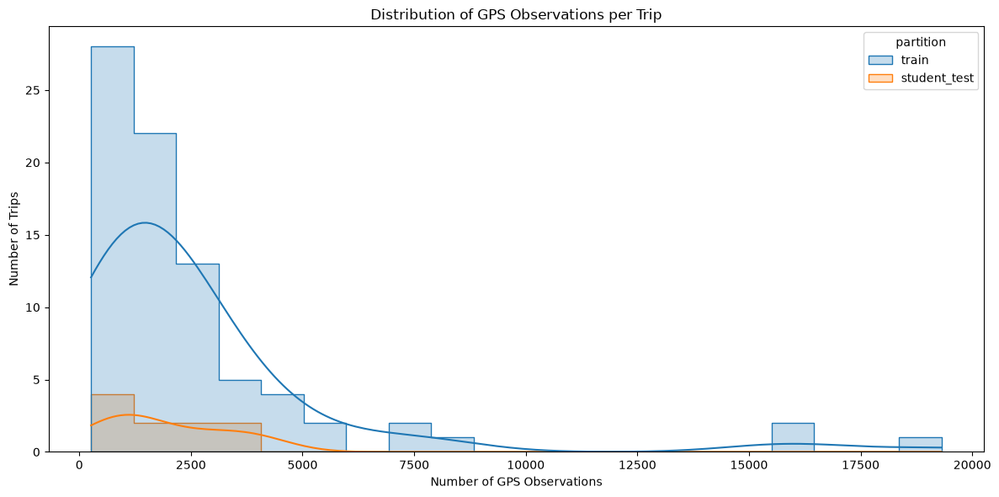

In [9]:

# CELL 7: GPS POINT DISTRIBUTION

plt.figure(figsize=(12, 6))

sns.histplot(
    data=gps_counts_df,
    x="gps_points",
    hue="partition",
    bins=20,
    kde=True,
    element="step"
)

plt.title("Distribution of GPS Observations per Trip")
plt.xlabel("Number of GPS Observations")
plt.ylabel("Number of Trips")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs" / "figures" / "gps_points_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [10]:

sampling_df.to_csv(
    PROJECT_DIR / "outputs" / "eda" / "sampling_interval_statistics.csv",
    index=False
)

gps_counts_df.to_csv(
    PROJECT_DIR / "outputs" / "eda" / "gps_points_per_trip.csv",
    index=False
)

print("EDA outputs saved successfully!")


EDA outputs saved successfully!


In [11]:

# CELL 9: DATA QUALITY ANALYSIS

def analyze_data_quality(directory, partition):

    records = []

    for trip_dir in sorted(directory.iterdir()):

        if not trip_dir.is_dir():
            continue

        file_path = trip_dir / f"{trip_dir.name}.track"

        track = pd.read_csv(
            file_path,
            sep=r"\s+",
            header=None,
            names=["longitude", "latitude", "timestamp"]
        )

        # Convert invalid values to NaN
        for col in ["longitude", "latitude", "timestamp"]:
            track[col] = pd.to_numeric(track[col], errors="coerce")

        records.append({
            "partition": partition,
            "trip_id": trip_dir.name,
            "total_points": len(track),
            "missing_longitude": track["longitude"].isna().sum(),
            "missing_latitude": track["latitude"].isna().sum(),
            "missing_timestamp": track["timestamp"].isna().sum(),
            "invalid_longitude": (
                ~track["longitude"].between(-180, 180)
            ).sum(),
            "invalid_latitude": (
                ~track["latitude"].between(-90, 90)
            ).sum(),
            "zero_or_negative_timestamp": (
                track["timestamp"] <= 0
            ).sum(),
            "duplicate_rows": track.duplicated().sum()
        })

    return records


quality_records = []

quality_records.extend(
    analyze_data_quality(TRAIN_DIR, "train")
)

quality_records.extend(
    analyze_data_quality(TEST_DIR, "student_test")
)

quality_df = pd.DataFrame(quality_records)

display(
    quality_df.groupby("partition").sum(numeric_only=True)
)


,total_points,missing_longitude,missing_latitude,missing_timestamp,invalid_longitude,invalid_latitude,zero_or_negative_timestamp,duplicate_rows
partition,,,,,,,,
student_test,19160,0,0,0,0,0,0,0
train,208417,0,0,0,0,0,0,0


In [12]:
quality_df.to_csv(
    PROJECT_DIR / "outputs" / "eda" / "data_quality.csv",
    index=False
)

print("Data quality report saved!")

Data quality report saved!


In [13]:
print("DATA QUALITY SUMMARY")
print("=" * 60)

display(
    quality_df.groupby("partition").sum(numeric_only=True)
)


DATA QUALITY SUMMARY


,total_points,missing_longitude,missing_latitude,missing_timestamp,invalid_longitude,invalid_latitude,zero_or_negative_timestamp,duplicate_rows
partition,,,,,,,,
student_test,19160,0,0,0,0,0,0,0
train,208417,0,0,0,0,0,0,0


In [14]:
print("Trips containing data-quality issues:")

issue_columns = [
    "missing_longitude",
    "missing_latitude",
    "missing_timestamp",
    "invalid_longitude",
    "invalid_latitude",
    "zero_or_negative_timestamp",
    "duplicate_rows"
]

display(
    quality_df[
        quality_df[issue_columns].sum(axis=1) > 0
    ]
)

Trips containing data-quality issues:


,partition,trip_id,total_points,missing_longitude,missing_latitude,missing_timestamp,invalid_longitude,invalid_latitude,zero_or_negative_timestamp,duplicate_rows


In [7]:
import folium

TRIP_ID = "00000001"

track = pd.read_csv(
    TRAIN_DIR / TRIP_ID / f"{TRIP_ID}.track",
    sep=r"\s+",
    header=None,
    names=["longitude", "latitude", "timestamp"]
)

print("GPS points:", len(track))
display(track.head())

GPS points: 1315


,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


In [18]:
gps_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=13,
    tiles=None,
    control_scale=True
)

# Esri basemap (no API key required)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri World Street Map"
).add_to(gps_map)

coordinates = list(zip(
    track["latitude"],
    track["longitude"]
))

folium.PolyLine(
    coordinates,
    color="blue",
    weight=4,
    opacity=0.8,
    tooltip="Raw GPS trajectory"
).add_to(gps_map)

folium.Marker(
    coordinates[0],
    popup="Trip Start",
    icon=folium.Icon(color="green")
).add_to(gps_map)

folium.Marker(
    coordinates[-1],
    popup="Trip End",
    icon=folium.Icon(color="red")
).add_to(gps_map)

gps_map.fit_bounds(coordinates)
display(gps_map)

In [19]:
MAP_DIR = PROJECT_DIR / "artifacts" / "maps"
MAP_DIR.mkdir(parents=True, exist_ok=True)

map_path = MAP_DIR / f"raw_gps_trip_{TRIP_ID}.html"

gps_map.save(str(map_path))

print("Map saved:", map_path)


Map saved: c:\Users\basub\ML-Hackathon-\artifacts\maps\raw_gps_trip_00000001.html


In [20]:
new_map_path = (
    PROJECT_DIR / "artifacts" / "maps"
    / "raw_gps_trip_00000001_cartodb.html"
)

gps_map.save(str(new_map_path))

print("Saved:", new_map_path)

Saved: c:\Users\basub\ML-Hackathon-\artifacts\maps\raw_gps_trip_00000001_cartodb.html


In [21]:
trip_id = "00000001"

nodes_file = TRAIN_DIR / trip_id / f"{trip_id}.nodes"
arcs_file = TRAIN_DIR / trip_id / f"{trip_id}.arcs"
route_file = TRAIN_DIR / trip_id / f"{trip_id}.route"

nodes = pd.read_csv(
    nodes_file,
    sep=r"\s+",
    header=None,
    names=["longitude", "latitude"]
)

arcs = pd.read_csv(
    arcs_file,
    sep=r"\s+",
    header=None,
    names=["source", "target"]
)

route = pd.read_csv(
    route_file,
    sep=r"\s+",
    header=None,
    names=["arc_id"]
)

print("Nodes:")
display(nodes.head())

print("Arcs:")
display(arcs.head())

print("Reference route:")
display(route.head())

print("Total nodes:", len(nodes))
print("Total arcs:", len(arcs))
print("Reference route entries:", len(route))

Nodes:


,longitude,latitude
0,8.581679,49.857880
1,8.584637,49.858295
2,8.580173,49.858567
3,8.584392,49.859119
4,8.584935,49.857396


Arcs:


,source,target
0,0,281
1,0,1
2,0,5
3,1,0
4,1,40750


Reference route:


,arc_id
0,2641
1,64973
2,133948
3,133949
4,139208


Total nodes: 88809
Total arcs: 165790
Reference route entries: 525


In [22]:
# Check whether route IDs are valid row indices in the arcs file

route_ids = route["arc_id"].astype(int)

print("Minimum route arc ID:", route_ids.min())
print("Maximum route arc ID:", route_ids.max())
print("Number of route entries:", len(route_ids))
print("Number of IDs within arc-row range:",
      route_ids.between(0, len(arcs) - 1).sum())

# Check whether consecutive route arcs connect
if route_ids.between(0, len(arcs) - 1).all():

    selected_arcs = arcs.iloc[route_ids.to_numpy()].reset_index(drop=True)

    continuity = (
        selected_arcs["target"].iloc[:-1].to_numpy()
        == selected_arcs["source"].iloc[1:].to_numpy()
    )

    print("Consecutive connected arcs:", continuity.sum())
    print("Consecutive disconnected arcs:", (~continuity).sum())

    display(selected_arcs.head(10))

else:
    print("Route IDs cannot all be used as zero-based arc row indices.")

Minimum route arc ID: 213
Maximum route arc ID: 165275
Number of route entries: 525
Number of IDs within arc-row range: 525
Consecutive connected arcs: 524
Consecutive disconnected arcs: 0


,source,target
0,1584,32308
1,32308,70987
2,70987,70988
3,70988,73922
4,73922,70989
5,70989,5218
6,5218,70990
7,70990,31877
8,31877,73925
9,73925,70991


In [23]:
# Reconstruct reference route using validated arc row indices

selected_arcs = arcs.iloc[route_ids.to_numpy()].reset_index(drop=True)

# Build ordered node sequence
route_node_ids = (
    [int(selected_arcs.iloc[0]["source"])]
    + selected_arcs["target"].astype(int).tolist()
)

# Convert node IDs into geographic coordinates
reference_coordinates = [
    (nodes.iloc[node_id]["latitude"],
     nodes.iloc[node_id]["longitude"])
    for node_id in route_node_ids
]

print("Reference route coordinates:", len(reference_coordinates))
print("First coordinate:", reference_coordinates[0])
print("Last coordinate:", reference_coordinates[-1])

Reference route coordinates: 526
First coordinate: (np.float64(49.839972), np.float64(8.594417))
Last coordinate: (np.float64(50.194084), np.float64(8.570447))


In [24]:
reference_layer = folium.FeatureGroup(
    name="Reference Route",
    show=True
)

folium.PolyLine(
    reference_coordinates,
    color="orange",
    weight=5,
    opacity=0.9,
    tooltip="Reference Route"
).add_to(reference_layer)

reference_layer.add_to(gps_map)

folium.LayerControl(collapsed=False).add_to(gps_map)

display(gps_map)

In [25]:
combined_map_path = (
    PROJECT_DIR / "artifacts" / "maps"
    / "gps_with_reference_route_00000001.html"
)

gps_map.save(str(combined_map_path))

print("Combined map saved:", combined_map_path)

Combined map saved: c:\Users\basub\ML-Hackathon-\artifacts\maps\gps_with_reference_route_00000001.html


In [26]:
# Sample road arcs for visualisation
# Keep the complete network in the original data.

ROAD_SAMPLE_SIZE = min(15000, len(arcs))

road_sample = arcs.sample(
    n=ROAD_SAMPLE_SIZE,
    random_state=42
)

road_layer = folium.FeatureGroup(
    name="Road Network (sampled)",
    show=False
)

for row in road_sample.itertuples(index=False):
    source_id = int(row.source)
    target_id = int(row.target)

    source_coord = [
        nodes.iloc[source_id]["latitude"],
        nodes.iloc[source_id]["longitude"]
    ]

    target_coord = [
        nodes.iloc[target_id]["latitude"],
        nodes.iloc[target_id]["longitude"]
    ]

    folium.PolyLine(
        [source_coord, target_coord],
        color="green",
        weight=1,
        opacity=0.35
    ).add_to(road_layer)

road_layer.add_to(gps_map)

print("Road segments added:", ROAD_SAMPLE_SIZE)

Road segments added: 15000


In [27]:
folium.LayerControl(collapsed=False).add_to(gps_map)
display(gps_map)

In [28]:
final_map_path = (
    PROJECT_DIR / "artifacts" / "maps"
    / "complete_trip_map_00000001.html"
)

gps_map.save(str(final_map_path))

print("Saved:", final_map_path)

Saved: c:\Users\basub\ML-Hackathon-\artifacts\maps\complete_trip_map_00000001.html


In [ ]:
road_records = (
    analyze_road_network(TRAIN_DIR, "train")
    + analyze_road_network(TEST_DIR, "student_test")
)

road_df = pd.DataFrame(road_records)

display(road_df.head())
display(road_df.groupby("partition").mean(numeric_only=True))

road_df.to_csv(
    PROJECT_DIR / "artifacts" / "eda" / "road_network_statistics.csv",
    index=False
)

print("Road network statistics saved successfully!")

,partition,trip_id,node_count,arc_count,connected_components,isolated_nodes
0,train,00000001,88809,165790,175,0
1,train,00000002,7936,16139,14,0
2,train,00000003,9138,18028,42,0
3,train,00000004,7350,15499,12,0
4,train,00000005,898,1579,3,0


,node_count,arc_count,connected_components,isolated_nodes
partition,,,,
student_test,9068.9000,18504.1,22.7000,0.0
train,24168.5625,48461.3,39.0125,0.0


Road network statistics saved successfully!


In [29]:
final_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=10,
    tiles=None
)

# Base map
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri Street Map"
).add_to(final_map)

# Raw GPS layer
gps_layer = folium.FeatureGroup(name="Raw GPS Trajectory")

folium.PolyLine(
    coordinates,
    color="blue",
    weight=3,
    tooltip="Raw GPS"
).add_to(gps_layer)

gps_layer.add_to(final_map)

# Reference route layer
reference_layer = folium.FeatureGroup(name="Reference Route")

folium.PolyLine(
    reference_coordinates,
    color="orange",
    weight=5,
    tooltip="Reference Route"
).add_to(reference_layer)

reference_layer.add_to(final_map)

# Road network layer
road_layer = folium.FeatureGroup(
    name="Road Network (sampled)",
    show=False
)

for row in road_sample.itertuples(index=False):
    source = int(row.source)
    target = int(row.target)

    folium.PolyLine(
        [
            [nodes.iloc[source, 1], nodes.iloc[source, 0]],
            [nodes.iloc[target, 1], nodes.iloc[target, 0]]
        ],
        color="green",
        weight=1,
        opacity=0.5
    ).add_to(road_layer)

road_layer.add_to(final_map)

# Add layer controls LAST
folium.LayerControl(collapsed=False).add_to(final_map)

final_map.fit_bounds(coordinates)

display(final_map)

In [31]:
final_map.save(
    str(PROJECT_DIR / "artifacts" / "maps" /
        "final_trip_map_00000001.html")
)

print("Final map saved successfully!")

Final map saved successfully!


In [32]:
def create_trip_map(
    trip_id,
    partition="train",
    predicted_coordinates=None,
    max_road_segments=5000
):
    """
    Create an interactive PathSnap trip map.

    predicted_coordinates:
        Optional list of (latitude, longitude) coordinate pairs.
    """

    # Select dataset partition
    data_dir = TRAIN_DIR if partition == "train" else TEST_DIR
    trip_dir = data_dir / str(trip_id)

    # Load trip files
    track = pd.read_csv(
        trip_dir / f"{trip_id}.track",
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    nodes = pd.read_csv(
        trip_dir / f"{trip_id}.nodes",
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude"]
    )

    arcs = pd.read_csv(
        trip_dir / f"{trip_id}.arcs",
        sep=r"\s+",
        header=None,
        names=["source", "target"]
    )

    route_file = trip_dir / f"{trip_id}.route"

    # Raw GPS coordinates
    gps_coordinates = list(zip(
        track["latitude"],
        track["longitude"]
    ))

    # Create fresh map
    trip_map = folium.Map(
        location=[
            track["latitude"].mean(),
            track["longitude"].mean()
        ],
        zoom_start=11,
        tiles=None
    )

    # Base layer
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles © Esri",
        name="Esri Street Map"
    ).add_to(trip_map)

    # Raw GPS layer
    gps_layer = folium.FeatureGroup(
        name="Raw GPS Trajectory"
    )

    folium.PolyLine(
        gps_coordinates,
        color="blue",
        weight=3,
        opacity=0.8
    ).add_to(gps_layer)

    gps_layer.add_to(trip_map)

    # Start and end markers
    folium.Marker(
        gps_coordinates[0],
        tooltip="Trip Start",
        icon=folium.Icon(color="green")
    ).add_to(trip_map)

    folium.Marker(
        gps_coordinates[-1],
        tooltip="Trip End",
        icon=folium.Icon(color="red")
    ).add_to(trip_map)

    # Reference route layer
    if route_file.exists():

        route = pd.read_csv(
            route_file,
            sep=r"\s+",
            header=None,
            names=["arc_id"]
        )

        route_ids = route["arc_id"].astype(int)

        if route_ids.between(0, len(arcs) - 1).all():

            selected_arcs = arcs.iloc[
                route_ids.to_numpy()
            ].reset_index(drop=True)

            sources = selected_arcs["source"].to_numpy()
            targets = selected_arcs["target"].to_numpy()

            # Check route continuity
            continuous = (
                (targets[:-1] == sources[1:]).all()
            )

            valid_nodes = (
                selected_arcs[["source", "target"]]
                .values.min() >= 0
                and
                selected_arcs[["source", "target"]]
                .values.max() < len(nodes)
            )

            if continuous and valid_nodes:

                route_node_ids = (
                    [int(sources[0])]
                    + targets.astype(int).tolist()
                )

                reference_coordinates = [
                    (
                        nodes.iloc[node_id]["latitude"],
                        nodes.iloc[node_id]["longitude"]
                    )
                    for node_id in route_node_ids
                ]

                reference_layer = folium.FeatureGroup(
                    name="Reference Route"
                )

                folium.PolyLine(
                    reference_coordinates,
                    color="orange",
                    weight=5,
                    opacity=0.9
                ).add_to(reference_layer)

                reference_layer.add_to(trip_map)

    # Road network layer: select segments within GPS bounds
    road_layer = folium.FeatureGroup(
        name="Road Network (sampled)",
        show=False
    )

    margin = 0.01

    min_lat = track["latitude"].min() - margin
    max_lat = track["latitude"].max() + margin
    min_lon = track["longitude"].min() - margin
    max_lon = track["longitude"].max() + margin

    nearby_nodes = nodes[
        nodes["latitude"].between(min_lat, max_lat)
        & nodes["longitude"].between(min_lon, max_lon)
    ]

    nearby_ids = set(nearby_nodes.index)

    nearby_arcs = arcs[
        arcs["source"].isin(nearby_ids)
        & arcs["target"].isin(nearby_ids)
    ]

    road_sample = nearby_arcs.sample(
        n=min(max_road_segments, len(nearby_arcs)),
        random_state=42
    )

    for row in road_sample.itertuples(index=False):

        source = int(row.source)
        target = int(row.target)

        coordinates_pair = [
            [
                nodes.iloc[source]["latitude"],
                nodes.iloc[source]["longitude"]
            ],
            [
                nodes.iloc[target]["latitude"],
                nodes.iloc[target]["longitude"]
            ]
        ]

        folium.PolyLine(
            coordinates_pair,
            color="green",
            weight=1,
            opacity=0.4
        ).add_to(road_layer)

    road_layer.add_to(trip_map)

    # Optional predicted route
    if predicted_coordinates is not None:

        predicted_layer = folium.FeatureGroup(
            name="Predicted Route"
        )

        folium.PolyLine(
            predicted_coordinates,
            color="purple",
            weight=5,
            opacity=0.9,
            tooltip="Predicted Route"
        ).add_to(predicted_layer)

        predicted_layer.add_to(trip_map)

    # Add controls once, after all layers
    folium.LayerControl(collapsed=False).add_to(trip_map)

    trip_map.fit_bounds(gps_coordinates)

    print("Trip:", trip_id)
    print("GPS points:", len(track))
    print("Road segments displayed:", len(road_sample))

    return trip_map

In [33]:
test_map = create_trip_map("00000001", partition="train")

display(test_map)

Trip: 00000001
GPS points: 1315
Road segments displayed: 5000


In [34]:
test_map_2 = create_trip_map("00000002", partition="train")

display(test_map_2)

Trip: 00000002
GPS points: 7243
Road segments displayed: 5000


In [35]:
test_map.save(
    str(PROJECT_DIR / "artifacts" / "maps" /
        "reusable_trip_map_00000001.html")
)

print("Reusable map saved!")

Reusable map saved!


In [36]:
test_map_2 = create_trip_map(
    "00000002",
    partition="train"
)

display(test_map_2)

Trip: 00000002
GPS points: 7243
Road segments displayed: 5000


In [37]:
test_map_2.save(
    str(PROJECT_DIR / "artifacts" / "maps" /
        "reusable_trip_map_00000002.html")
)

print("Second trip map saved!")

Second trip map saved!


In [39]:
print("DATA QUALITY SUMMARY")
print("=" * 60)

issue_columns = [
    "missing_longitude",
    "missing_latitude",
    "missing_timestamp",
    "invalid_longitude",
    "invalid_latitude",
    "zero_or_negative_timestamp",
    "duplicate_rows"
]

display(
    quality_df.groupby("partition")[issue_columns]
    .sum()
)

print("\nTrips containing at least one data-quality issue:")

display(
    quality_df[
        quality_df[issue_columns].sum(axis=1) > 0
    ][["partition", "trip_id"] + issue_columns]
)

print("\nTotal GPS observations:", gps_counts_df["count"].sum())

DATA QUALITY SUMMARY


NameError: name 'quality_df' is not defined

In [40]:
quality_df = pd.read_csv(
    PROJECT_DIR / "artifacts" / "eda" / "data_quality.csv"
)

sampling_df = pd.read_csv(
    PROJECT_DIR / "artifacts" / "eda" / "sampling_interval_statistics.csv"
)

gps_counts_df = pd.read_csv(
    PROJECT_DIR / "artifacts" / "eda" / "gps_points_per_trip.csv"
)

print("EDA data reloaded successfully!")
print("Quality records:", len(quality_df))
print("Sampling records:", len(sampling_df))

EDA data reloaded successfully!
Quality records: 90
Sampling records: 90


In [41]:
issue_columns = [
    "missing_longitude",
    "missing_latitude",
    "missing_timestamp",
    "invalid_longitude",
    "invalid_latitude",
    "zero_or_negative_timestamp",
    "duplicate_rows"
]

display(
    quality_df.groupby("partition")[issue_columns].sum()
)

display(
    quality_df[
        quality_df[issue_columns].sum(axis=1) > 0
    ][["partition", "trip_id"] + issue_columns]
)

,missing_longitude,missing_latitude,missing_timestamp,invalid_longitude,invalid_latitude,zero_or_negative_timestamp,duplicate_rows
partition,,,,,,,
student_test,0,0,0,0,0,0,0
train,0,0,0,0,0,0,0


,partition,trip_id,missing_longitude,missing_latitude,missing_timestamp,invalid_longitude,invalid_latitude,zero_or_negative_timestamp,duplicate_rows


In [42]:
display(
    sampling_df.groupby("partition")[
        [
            "mean_interval",
            "median_interval",
            "min_interval",
            "max_interval",
            "negative_intervals",
            "zero_intervals",
            "gaps_over_1_5s"
        ]
    ].mean()
)

,mean_interval,median_interval,min_interval,max_interval,negative_intervals,zero_intervals,gaps_over_1_5s
partition,,,,,,,
student_test,1.090549,1.0,1.0,25.5,0.0,0.0,26.4000
train,5.101888,1.0,1.0,2706.4,0.0,0.0,90.9125


In [43]:
import json
from pathlib import Path

# Load predicted route coordinates
with open("../../artifacts/predicted_coordinates_00000000.json") as f:
    predicted_coordinates = json.load(f)

# Generate map for student-test trip 00000000
m = create_trip_map(
    trip_id="00000000",
    partition="student_test",
    predicted_coordinates=predicted_coordinates
)

# Save interactive map
output_path = Path("../../artifacts/maps/predicted_route_trip_00000000.html")
output_path.parent.mkdir(parents=True, exist_ok=True)

m.save(str(output_path))

print("Map saved:", output_path.resolve())

Trip: 00000000
GPS points: 2503
Road segments displayed: 5000
Map saved: C:\Users\basub\ML-Hackathon-\artifacts\maps\predicted_route_trip_00000000.html


In [44]:
import folium
from folium import Element
from pathlib import Path

# Recreate the map
report_map = create_trip_map(
    trip_id="00000000",
    partition="student_test",
    predicted_coordinates=predicted_coordinates
)

# Hide the sampled road network by default
for layer in report_map._children.values():
    if isinstance(layer, folium.FeatureGroup):
        if "Road Network" in layer.layer_name:
            layer.show = False

# Add map title
title_html = """
<div style="
position: fixed;
top: 10px;
left: 50px;
z-index: 9999;
background: white;
padding: 10px 15px;
border: 1px solid grey;
border-radius: 5px;
font-size: 16px;
font-weight: bold;">
PathSnap — Predicted vs Reference Route (Trip 00000000)
</div>
"""

report_map.get_root().html.add_child(Element(title_html))

# Add legend
legend_html = """
<div style="
position: fixed;
bottom: 35px;
left: 35px;
z-index: 9999;
background: white;
padding: 12px;
border: 1px solid grey;
border-radius: 5px;
font-size: 13px;">
<b>Map Legend</b><br>
<span style="color:blue;">━━</span> Raw GPS Trajectory<br>
<span style="color:orange;">━━</span> Reference Route<br>
<span style="color:purple;">━━</span> Predicted Route<br>
<span style="color:green;">━━</span> Road Network
</div>
"""

report_map.get_root().html.add_child(Element(legend_html))

# Save
output = Path("../../artifacts/maps/report_ready_trip_00000000.html")
output.parent.mkdir(parents=True, exist_ok=True)
report_map.save(str(output))

print("Report-ready map saved:", output.resolve())

Trip: 00000000
GPS points: 2503
Road segments displayed: 5000
Report-ready map saved: C:\Users\basub\ML-Hackathon-\artifacts\maps\report_ready_trip_00000000.html
